### ESR Example of a Spin 1-1/2 Ferrimagnet 

In [3]:
# Import Python packages
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const

# Import the Simulation packages
project_directory = subprocess.check_output(['git', 'rev-parse', '--show-toplevel']).strip().decode('utf-8')
sys.path.append(project_directory + '/spinsimulation')  # Remove the square brackets
from SpinSys import SpinSys
import SpinHamiltonian as hamil 
import calcdIdV as dIdV
import calcESR as ESR
import SpinVisualization as vis
%load_ext autoreload
%autoreload 2

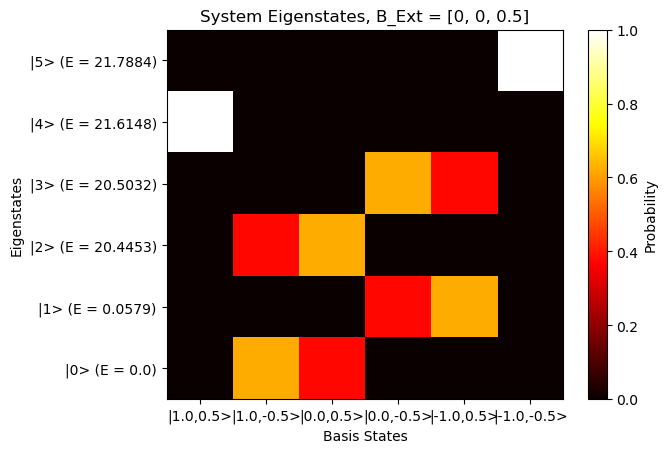

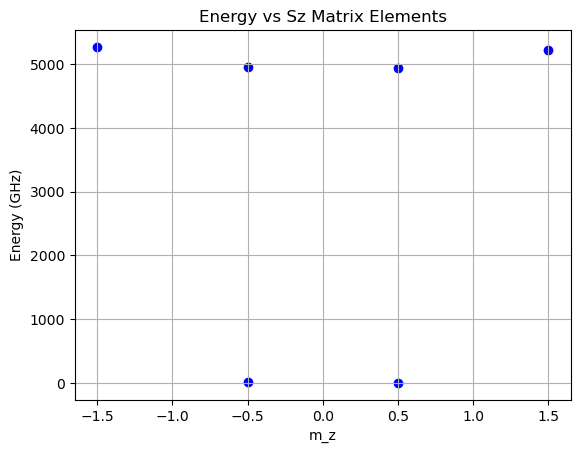

In [23]:
# Define the Spin System
spinsys=SpinSys([1,0.5])

# Add the Spin Hamiltonian parameters
spinsys.B=[0,0,0.5] #Add a magnetic field in Tesla
spinsys.BTip=[1e-7,0,0] # Add a tipfield for driving
spinsys.T=1 
spinsys.Jvector=np.array([[14,14,14]]) # Exchange coupling in meV
spinsys.Dvector=np.array([1.9,0])  # Anisotropy of the Spin 1
spinsys.AtomPositions=np.array([[0,0,0],[2,1,0]]) # Positions of the atoms in lattice units
spinsys.DipoleBool=[False] # Dipole interaction is not included

vis.plotEigenMatrix(spinsys)
vis.plotEnergyVsSz(spinsys)
#vis.plotZeemanDiagramm(spinsys)

Found 1 potential transitions:
|0> -> |1>; f = 13.9953 GHz


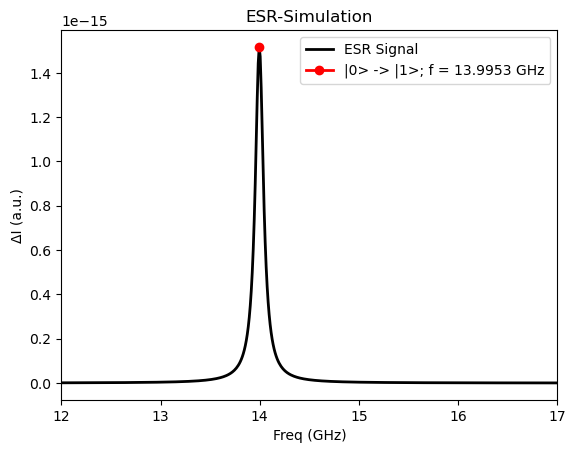

In [20]:
# ESR Calculation
spinsys.ReadoutSpin=0 # Set the readout spin
vis.plotESR_FreqSweep(spinsys, FreqRange=[12,17],N=500, norm=False, lw=0.1,AllowPumping=False)

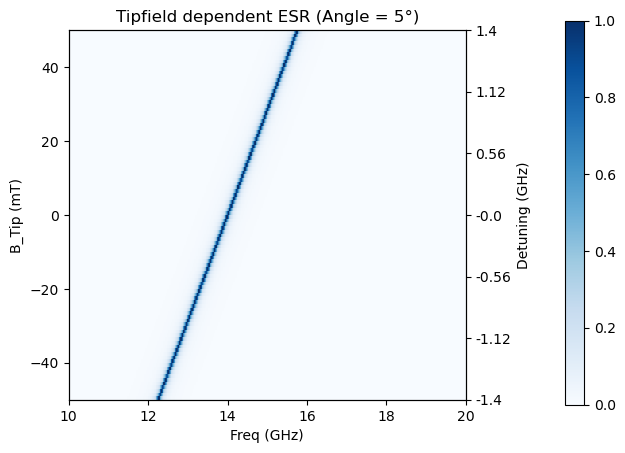

In [22]:
# Tipfield dependent ESR
vis.plotESR_Tipfieldsweep(spinsys, Angle=5,lw=0.1)